# Vẽ hiện tượng mắc kẹt tại cực tiểu địa phương (mục 5.1.4): f(x) = x^4 - 3x^2 + x

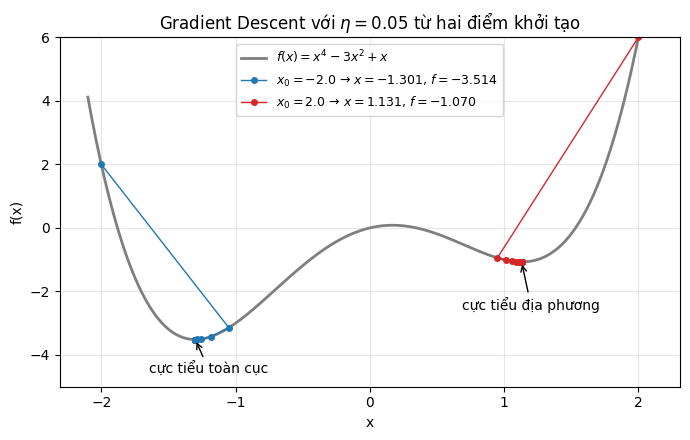

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

def f(x):
    return x**4 - 3 * x**2 + x

def grad(x):
    """Đạo hàm f'(x)."""
    return 4 * x**3 - 6 * x + 1

def gd(x0, eta=0.05, n_iters=50):
    """GD từ x0 với số vòng lặp cố định; trả về dãy x."""
    x = x0
    history = [x0]
    for _ in range(n_iters):
        x = x - eta * grad(x)
        history.append(x)
    return np.array(history)

x_line = np.linspace(-2.1, 2.1, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x_line, f(x_line), color="#7F7F7F", lw=2, label=r"$f(x) = x^4 - 3x^2 + x$")
for x0, color in [(-2.0, "#1F77B4"), (2.0, "#D62728")]:
    x_history = gd(x0)
    ax.plot(x_history, f(x_history), "o-", color=color, ms=4, lw=1,
            label=f"$x_0 = {x0}$ → $x = {x_history[-1]:.3f}$, $f = {f(x_history[-1]):.3f}$")
ax.annotate("cực tiểu toàn cục", (-1.30, f(-1.30)), (-1.2, -4.6), ha="center",
            arrowprops=dict(arrowstyle="->"))
ax.annotate("cực tiểu địa phương", (1.13, f(1.13)), (1.2, -2.6), ha="center",
            arrowprops=dict(arrowstyle="->"))
ax.set_ylim(-5, 6)
ax.set_xlabel("x"); ax.set_ylabel("f(x)")
ax.set_title(r"Gradient Descent với $\eta = 0.05$ từ hai điểm khởi tạo")
ax.legend(loc="upper center", fontsize=9); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "local_minima.png", dpi=150)